# Tables, SQL and charts in a TypeScript notebook

Three calls on the `jupyter` namespace turn data into output that every reader can show: the Ganymede apps, JupyterLab, VS Code, a published page, and an agent reading the notebook as text.

- `jupyter.table` shows rows as a table.
- `` jupyter.sql`...` `` runs SQL on an in-memory DuckDB database; results show as tables.
- `jupyter.chart` draws a Vega-Lite spec or an Observable Plot chart as one SVG.

Each output also carries a short text summary, which is what an agent or a terminal sees.

## Rows as a table

An array of objects is enough. Each column's type comes from its values and shows under its name.

In [1]:
const moons = [
  { moon: "Io", radius_km: 1821.6, period_days: 1.769, discovered: new Date("1610-01-08"), group: "Galilean" },
  { moon: "Europa", radius_km: 1560.8, period_days: 3.551, discovered: new Date("1610-01-08"), group: "Galilean" },
  { moon: "Ganymede", radius_km: 2634.1, period_days: 7.155, discovered: new Date("1610-01-07"), group: "Galilean" },
  { moon: "Callisto", radius_km: 2410.3, period_days: 16.689, discovered: new Date("1610-01-07"), group: "Galilean" },
  { moon: "Amalthea", radius_km: 83.5, period_days: 0.498, discovered: new Date("1892-09-09"), group: "Inner" },
  { moon: "Thebe", radius_km: 49.3, period_days: 0.675, discovered: new Date("1979-03-05"), group: "Inner" },
  { moon: "Metis", radius_km: 21.5, period_days: 0.295, discovered: new Date("1979-03-04"), group: "Inner" },
  { moon: "Himalia", radius_km: 69.8, period_days: 250.56, discovered: new Date("1904-12-03"), group: "Irregular" },
  { moon: "Elara", radius_km: 43, period_days: 259.64, discovered: new Date("1905-01-05"), group: "Irregular" },
];
jupyter.table(moons, { title: "Some moons of Jupiter" });

moonstring,radius_kmnumber,period_daysnumber,discovereddate,groupstring
Io,1821.6,1.769,1610-01-08,Galilean
Europa,1560.8,3.551,1610-01-08,Galilean
Ganymede,2634.1,7.155,1610-01-07,Galilean
Callisto,2410.3,16.689,1610-01-07,Galilean
Amalthea,83.5,0.498,1892-09-09,Inner
Thebe,49.3,0.675,1979-03-05,Inner
Metis,21.5,0.295,1979-03-04,Inner
Himalia,69.8,250.56,1904-12-03,Irregular
Elara,43,259.64,1905-01-05,Irregular


## SQL over the notebook's own rows

`jupyter.sql.load` makes a DuckDB table from rows the notebook already has. In the tag, a `${value}` can't change the query: it is a bound parameter (a quoted literal in the browser).

In [2]:
await jupyter.sql.load("moons", moons);
const minRadius = 1000;
await jupyter.sql`
  select moon, radius_km, round(radius_km / 1737.4, 2) as moon_radii
  from moons
  where radius_km > ${minRadius}
  order by radius_km desc`;

moonstring,radius_kmnumber,moon_radiinumber
Ganymede,2634.1,1.52
Callisto,2410.3,1.39
Io,1821.6,1.05
Europa,1560.8,0.9


## SQL over a file on the web

DuckDB reads CSV, Parquet and JSON by path or URL. This is four years of Seattle weather from the Vega datasets.

In [3]:
await jupyter.sql.load("weather", "https://raw.githubusercontent.com/vega/vega-datasets/v2.11.0/data/seattle-weather.csv");
await jupyter.sql`
  select weather, count(*) as days, round(avg(precipitation), 2) as avg_precip_mm
  from weather
  group by weather
  order by days desc`;

weatherstring,daysinteger,avg_precip_mmnumber
rain,641,6.56
sun,640,0
fog,101,0
drizzle,53,0
snow,26,8.55


## A chart from a query, with Vega-Lite

A query's `rows` are plain objects, ready for a chart. The chart is drawn in the kernel, so the notebook holds an SVG that shows anywhere, with no chart library in the reader.

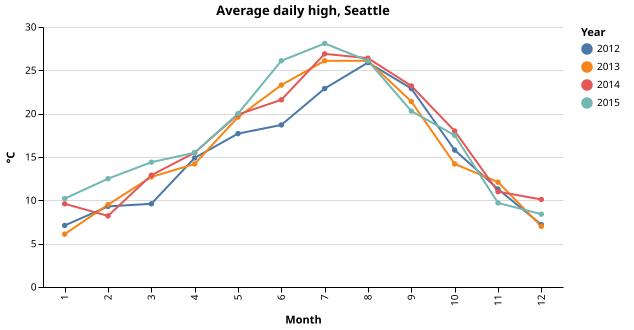

In [4]:
const monthly = await jupyter.sql`
  select month(date) as month, year(date)::varchar as year, round(avg(temp_max), 1) as avg_high_c
  from weather
  group by all
  order by year, month`;

jupyter.chart({
  title: "Average daily high, Seattle",
  width: 520,
  height: 260,
  data: { values: monthly.rows },
  mark: { type: "line", point: true },
  encoding: {
    x: { field: "month", type: "ordinal", title: "Month" },
    y: { field: "avg_high_c", type: "quantitative", title: "°C" },
    color: { field: "year", type: "nominal", title: "Year" },
  },
});

## The same data with Observable Plot

Pass the Plot module and the options you would give `Plot.plot`. The title, subtitle and legend are drawn into the SVG, so they survive where a reader shows only images.

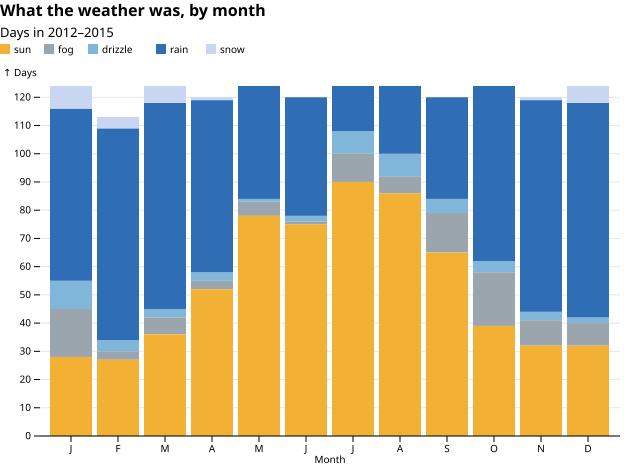

In [5]:
import * as Plot from "npm:@observablehq/plot@0.6";

const byMonth = await jupyter.sql`
  select month(date) as month, weather, count(*) as days
  from weather
  group by all
  order by month, weather`;

jupyter.chart(Plot, {
  title: "What the weather was, by month",
  subtitle: "Days in 2012–2015",
  width: 640,
  color: { legend: true, domain: ["sun", "fog", "drizzle", "rain", "snow"], range: ["#f2b134", "#9aa5ad", "#7fb6d9", "#2f6db5", "#c9d6f2"] },
  x: { label: "Month", tickFormat: (m) => "JFMAMJJASOND"[m - 1] },
  y: { label: "Days", grid: true },
  marks: [Plot.barY(byMonth.rows, { x: "month", y: "days", fill: "weather", order: ["sun", "fog", "drizzle", "rain", "snow"] }), Plot.ruleY([0])],
});

A continuous color scale gets a ramp instead of swatches:

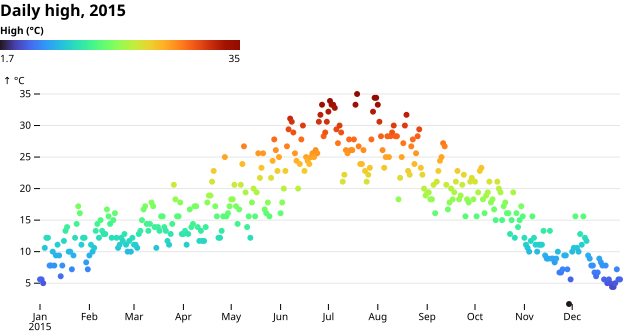

In [6]:
const days = await jupyter.sql`select date, temp_max, temp_min from weather where year(date) = 2015`;
jupyter.chart(Plot, {
  title: "Daily high, 2015",
  width: 640,
  height: 260,
  color: { legend: true, scheme: "turbo", label: "High (°C)" },
  y: { label: "°C", grid: true },
  marks: [Plot.dot(days.rows, { x: "date", y: "temp_max", fill: "temp_max", r: 3 })],
});

## Large results

A result shows up to 1,000 rows and always says how many there are. `jupyter.table(result, { limit })` sets a different cap, up to 10,000. The apps page through the rows and sort by any column; a published page shows the first 100.

In [7]:
const all = await jupyter.sql`select * from weather order by date`;
jupyter.table(all, { limit: 200, title: "Seattle weather, 2012–2015" });

datedate,precipitationnumber,temp_maxnumber,temp_minnumber,windnumber,weatherstring
2012-01-01,0,12.8,5,4.7,drizzle
2012-01-02,10.9,10.6,2.8,4.5,rain
2012-01-03,0.8,11.7,7.2,2.3,rain
2012-01-04,20.3,12.2,5.6,4.7,rain
2012-01-05,1.3,8.9,2.8,6.1,rain
2012-01-06,2.5,4.4,2.2,2.2,rain
2012-01-07,0,7.2,2.8,2.3,rain
2012-01-08,0,10,2.8,2,sun
2012-01-09,4.3,9.4,5,3.4,rain
2012-01-10,1,6.1,0.6,3.4,rain


## What an agent sees

Every one of these outputs carries a `text/plain` summary: the column types and ranges for a table, the marks and scales for a chart. That is what an agent reads, and what `jupyter console` prints.

In [8]:
console.log((await jupyter.format(all))["text/plain"]);

Table (1,461 rows, 6 columns; 1,000 shown)
Columns (ranges over the first 1,000 of 1,461 rows):
  date           date    2012-01-01 to 2014-09-26
  precipitation  number  0 to 54.1
  temp_max       number  -1.6 to 35.6
  temp_min       number  -7.1 to 18.3
  wind           number  0.4 to 9.5
  weather        string  5 values
Rows:
  0    | 2012-01-01 | 0    | 12.8 | 5    | 4.7 | drizzle
  1    | 2012-01-02 | 10.9 | 10.6 | 2.8  | 4.5 | rain
  2    | 2012-01-03 | 0.8  | 11.7 | 7.2  | 2.3 | rain
  …
  1459 | 2015-12-30 | 0    | 5.6  | -1   | 3.4 | sun
  1460 | 2015-12-31 | 0    | 5.6  | -2.1 | 3.5 | sun
